# 01 — Data-source EDA: what can Open-Meteo and SNOTEL actually give us?

**Canvas project group:** TODO · **Members:** TODO

**Purpose.** Before collecting the modelling dataset, we probed both data sources to decide *which places, which
model/product, which variables and how many winters*. This notebook reproduces **every** check behind those
decisions so that each one can be traced to evidence. Decisions are logged in `docs/DECISIONS.md` (IDs `D-xxx`
are cited below); data-source facts in `docs/DATA_SOURCES.md`.

**Data lineage.** Every download goes through `src/lineage.py::fetch()`, which
1. builds one canonical URL from the query parameters,
2. saves the raw response body **unmodified** to `data/raw/<source>/<name>__<hash>.json`,
3. appends a row to `data/raw/MANIFEST.csv` (UTC time, URL, file, bytes, SHA-256, HTTP status).

Re-running the notebook reads the cached raw files, so results are reproducible even if an API changes. To
re-download, delete the file (or pass `refresh=True`). Error responses (HTTP 400) are kept too — they are evidence.
Rate-limit / server errors are logged but never cached.

**Sources.**
- Open-Meteo Historical Weather API — https://open-meteo.com/en/docs/historical-weather-api (required by staff, D-001)
- NRCS SNOTEL via the AWDB REST API — https://wcc.sc.egov.usda.gov/awdbRestApi/swagger-ui/index.html

**Contents.** §1 Open-Meteo · §2 SNOTEL · §3 Open-Meteo vs SNOTEL validation · §4 Aspen as one resort ·
§5 Choosing three resorts · §6 Data volume & lineage · §7 Summary of findings → decisions

In [1]:
import sys, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import lineage, parse, sites
from lineage import open_meteo, snotel

pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.titlesize": 13, "axes.labelsize": 11})
ST_ANTON = sites.SKI_AREAS["St. Anton (AT)"]   # original proposal site — Open-Meteo-only probes
ASPEN = sites.SKI_AREAS["Aspen Mountain"]
print("project root:", ROOT)

project root: /Users/owen/DataSci1/Final Project


## 1. Open-Meteo Historical Weather API

`https://archive-api.open-meteo.com/v1/archive` — free, no key, any lat/lon, daily or hourly. The `models=`
parameter selects the underlying dataset:

| model | what it is |
|---|---|
| `era5` | ECMWF ERA5 reanalysis, 0.25° (~25 km), 1940→ |
| `era5_land` | ERA5-Land, 0.1° (~9 km), land-surface variables only, 1950→ |
| `era5_seamless` | Open-Meteo blend of ERA5 + ERA5-Land |
| `ecmwf_ifs` | ECMWF operational IFS analysis, ~9 km |
| `cerra` | Copernicus European regional reanalysis, 5.5 km, **Europe only** |
| `best_match` | the default: Open-Meteo picks "the best" model per period/location |

### 1.1 Same day, every model
2021-01-10 at St. Anton (original proposal) and at Aspen Mountain. `null` = model does not provide it.

In [2]:
MODELS = ["best_match", "era5", "era5_land", "era5_seamless", "ecmwf_ifs", "cerra"]
DAILY_PROBE = ["temperature_2m_mean", "snowfall_sum", "snow_depth_mean", "sunshine_duration", "wind_speed_10m_max"]

def one_day(lat, lon, day, model, label):
    p = dict(latitude=lat, longitude=lon, start_date=day, end_date=day,
             daily=DAILY_PROBE, models=model, timezone="auto")
    j = open_meteo(p, name=f"oneday_{label}_{model}_{day}")
    if j.get("error"):
        return {"model": model, "error": j["reason"]}
    return {"model": model, "grid_elev_m": j["elevation"],
            **{k: v[0] for k, v in j["daily"].items() if k != "time"}}

for label, (lat, lon) in [("stanton", ST_ANTON), ("aspen", ASPEN)]:
    print(f"\n=== {label} 2021-01-10 ===")
    display(pd.DataFrame([one_day(lat, lon, "2021-01-10", m, label) for m in MODELS]).set_index("model"))


=== stanton 2021-01-10 ===


,grid_elev_m,temperature_2m_mean,snowfall_sum,snow_depth_mean,sunshine_duration,wind_speed_10m_max
model,,,,,,
best_match,1286.0,-4.2,0.0,0.72,30897.96,6.0
era5,1286.0,-14.4,0.0,NaN,30844.83,6.8
era5_land,1286.0,-12.7,NaN,0.72,NaN,NaN
era5_seamless,1286.0,-12.7,0.0,0.72,30914.27,6.8
ecmwf_ifs,1286.0,-4.2,0.0,NaN,30897.96,6.0
cerra,1286.0,-11.6,0.0,1.12,29421.72,4.7



=== aspen 2021-01-10 ===


,grid_elev_m,temperature_2m_mean,snowfall_sum,snow_depth_mean,sunshine_duration,wind_speed_10m_max,error
model,,,,,,,
best_match,2423.0,-11.6,0.0,0.34,33193.07,7.3,NaN
era5,2423.0,-8.3,0.0,NaN,33154.71,8.7,NaN
era5_land,2423.0,-9.8,NaN,0.34,NaN,NaN,NaN
era5_seamless,2423.0,-9.8,0.0,0.34,33175.24,8.7,NaN
ecmwf_ifs,2423.0,-11.6,0.0,NaN,33193.07,7.3,NaN
cerra,NaN,NaN,NaN,NaN,NaN,NaN,No data is available for this location


**Observation.** Models disagree by up to ~10 °C on the same day at St. Anton. Variable support also differs:
ERA5 has no snow depth, while ERA5-Land has no snowfall, sunshine or wind. CERRA has no data over Aspen because it covers Europe only.

### 1.2 Coverage over time, and the `best_match` break
Daily series 1995-01-01 → 2026-10-31 for each model at St. Anton (3 variables). For each model/variable, the table shows
the first and last non-null date and the % of days with data.

In [3]:
SERIES_VARS = ["temperature_2m_mean", "snowfall_sum", "snow_depth_mean"]

def om_series(lat, lon, model, label, start="1995-01-01", end="2026-10-31", daily=SERIES_VARS, **extra):
    p = dict(latitude=lat, longitude=lon, start_date=start, end_date=end, daily=list(daily),
             models=model, timezone="auto", **extra)
    return parse.open_meteo_daily(open_meteo(p, name=f"series_{label}_{model}"))

stanton = {m: om_series(*ST_ANTON, m, "stanton") for m in MODELS}

rows = []
for m, df in stanton.items():
    for v in SERIES_VARS:
        nn = df[v].dropna()
        rows.append({"model": m, "variable": v,
                     "first": nn.index.min().date() if len(nn) else None,
                     "last": nn.index.max().date() if len(nn) else None,
                     "% days non-null": round(100 * df[v].notna().mean(), 1)})
coverage_om = pd.DataFrame(rows).set_index(["model", "variable"])
coverage_om

first        last  % days non-null
model         variable                                                    
best_match    temperature_2m_mean  1995-01-01  2026-10-31            100.0
              snowfall_sum         1995-01-01  2026-10-31            100.0
              snow_depth_mean      1995-01-01  2026-10-31            100.0
era5          temperature_2m_mean  1995-01-01  2026-10-31            100.0
              snowfall_sum         1995-01-01  2026-10-31            100.0
              snow_depth_mean            None        None              0.0
era5_land     temperature_2m_mean  1995-01-01  2026-10-31            100.0
              snowfall_sum               None        None              0.0
              snow_depth_mean      1995-01-01  2026-10-31            100.0
era5_seamless temperature_2m_mean  1995-01-01  2026-10-31            100.0
              snowfall_sum         1995-01-01  2026-10-31            100.0
              snow_depth_mean      1995-01-01  2026-10-31            100.0
ecmwf_ifs     temperature_2m_mean  2017-01-02  2026-10-31             30.9
              snowfall_sum         2017-01-02  2026-10-31             30.9
              snow_depth_mean      2025-01-10  2026-10-31              3.4
cerra         temperature_2m_mean  1995-01-01  2021-06-30             83.2
              snowfall_sum         1995-01-01  2021-06-30             83.2
              snow_depth_mean      1995-01-01  2021-06-30             83.2

In [4]:
# Which model does best_match actually return? Fraction of days per year where best_match == model (|diff| < 0.05 °C)
T = pd.DataFrame({m: df["temperature_2m_mean"] for m, df in stanton.items()})
match = pd.DataFrame({m: (T["best_match"] - T[m]).abs().lt(0.05).groupby(T.index.year).mean()
                      for m in ["era5_land", "era5", "ecmwf_ifs", "cerra"]}).round(2)
match.index.name = "year"
match.loc[2010:]

,era5_land,era5,ecmwf_ifs,cerra
year,,,,
2010,1.00,0.04,0.0,0.03
2011,1.00,0.05,0.0,0.02
2012,1.00,0.04,0.0,0.04
2013,1.00,0.04,0.0,0.04
2014,1.00,0.06,0.0,0.04
2015,1.00,0.04,0.0,0.01
2016,1.00,0.02,0.0,0.02
2017,0.04,0.04,1.0,0.03
2018,0.03,0.04,1.0,0.03


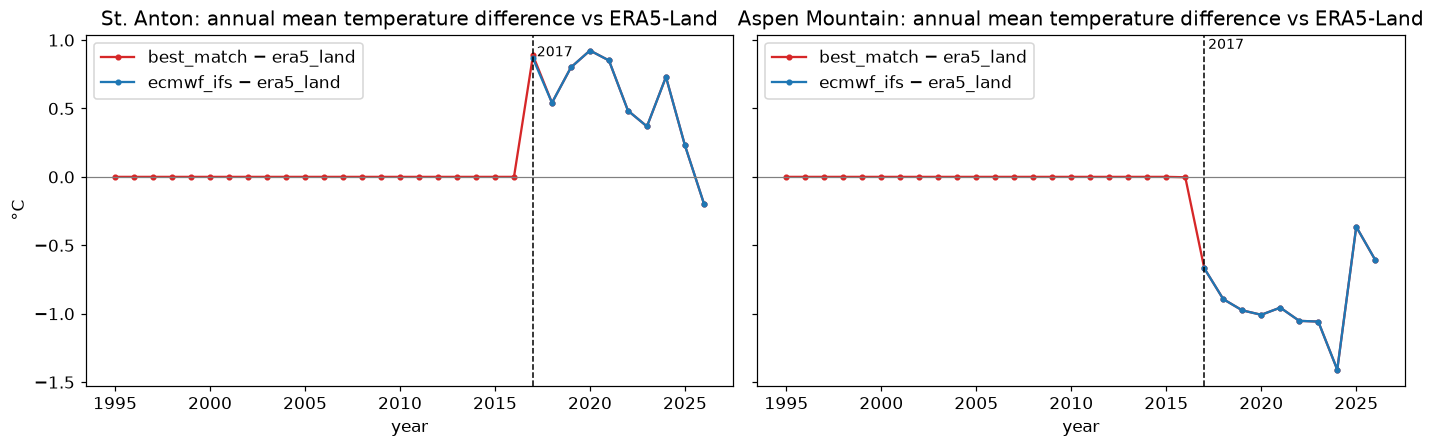

In [5]:
aspen_bm = {m: om_series(*ASPEN, m, "aspen", daily=["temperature_2m_mean"]) for m in ["best_match", "era5_land", "ecmwf_ifs"]}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (title, d) in zip(axes, [("St. Anton", stanton), ("Aspen Mountain", aspen_bm)]):
    base = d["era5_land"]["temperature_2m_mean"]
    for m, c in [("best_match", "tab:red"), ("ecmwf_ifs", "tab:blue")]:
        diff = (d[m]["temperature_2m_mean"] - base).groupby(base.index.year).mean()
        ax.plot(diff.index, diff.values, marker="o", ms=3, color=c, label=f"{m} − era5_land")
    ax.axvline(2017, color="k", ls="--", lw=1); ax.text(2017.2, ax.get_ylim()[1]*0.9 if ax.get_ylim()[1] > 0 else 0.5, "2017", fontsize=9)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(f"{title}: annual mean temperature difference vs ERA5-Land")
    ax.set_xlabel("year"); ax.legend(loc="upper left")
axes[0].set_ylabel("°C")
plt.tight_layout(); plt.show()

**Finding → D-002.** The match table shows that `best_match` equals ERA5-Land on **100 %** of days in every year through 2016,
and equals ECMWF IFS on **100 %** of days in every year from 2017. Its annual mean temperature jumps by several °C at that point, at both
sites. IFS snow depth only exists from 2025-01-10. Our test set is the *later* winters, so the jump would fall right on the
train/test boundary. **We pin models explicitly and never use `best_match`.** CERRA ends on 2021-06-30 (83 % coverage of
1995–2026) and has no data for Aspen.

### 1.3 What does the `elevation=` parameter do?
Open-Meteo applies a lapse-rate correction for the requested elevation. We test which variables it changes.
Without `elevation`, the API uses the grid cell's mean terrain height, shown in the "default" row.

In [6]:
def elev_probe(lat, lon, label, elevs, day="2020-01-15", model="era5_seamless"):
    out = []
    for e in [None] + elevs:
        p = dict(latitude=lat, longitude=lon, start_date=day, end_date=day, models=model, timezone="auto",
                 daily=["temperature_2m_mean", "snowfall_sum", "snow_depth_mean", "precipitation_sum"])
        if e is not None:
            p["elevation"] = e
        j = open_meteo(p, name=f"elev_{label}_{e}")
        out.append({"requested_elev": "default" if e is None else e, "elev_used_m": j["elevation"],
                    **{k: v[0] for k, v in j["daily"].items() if k != "time"}})
    return pd.DataFrame(out).set_index("requested_elev")

display(elev_probe(*ST_ANTON, "stanton", [1300, 2000, 2800]))
display(elev_probe(*ASPEN, "aspen", [2400, 3000, 3400]))

,elev_used_m,temperature_2m_mean,snowfall_sum,snow_depth_mean,precipitation_sum
requested_elev,,,,,
default,1286.0,-3.6,0.0,1.16,0.0
1300,1300.0,-3.7,0.0,1.16,0.0
2000,2000.0,-8.3,0.0,1.16,0.0
2800,2800.0,-13.5,0.0,1.16,0.0


,elev_used_m,temperature_2m_mean,snowfall_sum,snow_depth_mean,precipitation_sum
requested_elev,,,,,
default,2423.0,-6.5,0.0,0.69,0.0
2400,2400.0,-6.3,0.0,0.69,0.0
3000,3000.0,-10.2,0.0,0.69,0.0
3400,3400.0,-12.2,0.0,0.73,0.0


**Finding.** Temperature follows the requested elevation (Aspen: −6.3 °C at 2400 m → −12.2 °C at 3400 m). Snowfall and
precipitation do not change, and snow depth changes only slightly (St. Anton: 1.16 m at every elevation; Aspen: 0.69 → 0.73 m at 3400 m,
possibly because a different nearby grid cell is picked). **Snow is a grid-cell quantity, so reanalysis cannot tell the base area
from the summit.** That is the main argument for measured on-mountain snow data (§2, D-003).

### 1.4 Which variables does each model actually provide?
One winter (2023-11-01 → 2024-04-30) at Aspen Mountain. The table shows the % of non-null days or hours per variable for each model.

In [7]:
ALL_DAILY = ["weather_code", "temperature_2m_max", "temperature_2m_min", "temperature_2m_mean",
             "apparent_temperature_mean", "precipitation_sum", "rain_sum", "snowfall_sum",
             "snowfall_water_equivalent_sum", "precipitation_hours", "sunshine_duration", "daylight_duration",
             "wind_speed_10m_max", "wind_gusts_10m_max", "wind_direction_10m_dominant", "shortwave_radiation_sum",
             "cloud_cover_mean", "relative_humidity_2m_mean", "pressure_msl_mean", "snow_depth_mean", "snow_depth_max"]
ALL_HOURLY = ["snow_depth", "snow_depth_water_equivalent", "freezing_level_height", "visibility",
              "cloud_cover_low", "boundary_layer_height"]
avail = {}
for m in ["era5", "era5_land", "era5_seamless"]:
    p = dict(latitude=ASPEN[0], longitude=ASPEN[1], start_date="2023-11-01", end_date="2024-04-30",
             daily=ALL_DAILY, hourly=ALL_HOURLY, models=m, timezone="auto")
    j = open_meteo(p, name=f"vars_aspen_{m}")
    d = {f"daily:{k}": 100 * pd.Series(v).notna().mean() for k, v in j["daily"].items() if k != "time"}
    d |= {f"hourly:{k}": 100 * pd.Series(v).notna().mean() for k, v in j["hourly"].items() if k != "time"}
    avail[m] = d
avail = pd.DataFrame(avail).round(0)
avail

,era5,era5_land,era5_seamless
daily:weather_code,100.0,0.0,100.0
daily:temperature_2m_max,100.0,100.0,100.0
daily:temperature_2m_min,100.0,100.0,100.0
daily:temperature_2m_mean,100.0,100.0,100.0
daily:apparent_temperature_mean,100.0,0.0,100.0
daily:precipitation_sum,100.0,0.0,100.0
daily:rain_sum,100.0,0.0,100.0
daily:snowfall_sum,100.0,0.0,100.0
daily:snowfall_water_equivalent_sum,100.0,0.0,100.0
daily:precipitation_hours,100.0,100.0,100.0


**Finding.** `era5` provides the atmospheric variables (snowfall, sunshine, wind, cloud) but not snow depth.
`era5_land` provides temperature and snow depth (daily `snow_depth_mean`/`max` exist). `era5_seamless` combines both.
Freezing level, visibility and hourly snow-water-equivalent are empty in the archive.

### 1.5 Other Open-Meteo APIs: is there an archived *30-day forecast* we could compare against?

In [8]:
SEASONAL = "https://seasonal-api.open-meteo.com/v1/seasonal"
HISTFC = "https://historical-forecast-api.open-meteo.com/v1/forecast"
PREVRUNS = "https://previous-runs-api.open-meteo.com/v1/forecast"
CLIMATE = "https://climate-api.open-meteo.com/v1/climate"
lat, lon = ASPEN

j = open_meteo(dict(latitude=lat, longitude=lon, daily="temperature_2m_max", start_date="2020-01-01", end_date="2020-01-05"),
               name="seasonal_2020", base=SEASONAL)
print("Seasonal (ECMWF SEAS5), Jan 2020 ->", j.get("reason"))

j = open_meteo(dict(latitude=lat, longitude=lon, daily="temperature_2m_max", past_days=92, forecast_days=183),
               name="seasonal_current_snapshot_2026-11-09", base=SEASONAL)
members = [k for k in j["daily"] if "member" in k]
print(f"Seasonal current snapshot: {j['daily']['time'][0]} -> {j['daily']['time'][-1]}, {len(members) + 1} ensemble members")

for day in ["2016-01-15", "2017-06-01", "2018-01-15"]:
    j = open_meteo(dict(latitude=lat, longitude=lon, start_date=day, end_date=day, daily="temperature_2m_mean"),
                   name=f"histforecast_{day}", base=HISTFC)
    print(f"Historical-forecast API {day}:", j.get("reason") or j["daily"]["temperature_2m_mean"])

j = open_meteo(dict(latitude=lat, longitude=lon, start_date="2024-01-15", end_date="2024-01-15",
                    hourly=["temperature_2m", "temperature_2m_previous_day1", "temperature_2m_previous_day7"]),
               name="previousruns_2024-01-15", base=PREVRUNS)
print("Previous-runs API, 2024-01-15 12:00:", j.get("reason") or {k: v[12] for k, v in j["hourly"].items()})

j = open_meteo(dict(latitude=lat, longitude=lon, start_date="2020-01-15", end_date="2020-01-15",
                    models="EC_Earth3P_HR", daily=["temperature_2m_mean", "snowfall_sum"]),
               name="climate_2020-01-15", base=CLIMATE)
print("Climate (CMIP6 EC_Earth3P_HR) 2020-01-15:", j.get("reason") or j["daily"])

Seasonal (ECMWF SEAS5), Jan 2020 -> Parameter 'start_date' is out of allowed range from 2025-09-01 to 2027-06-14
Seasonal current snapshot: 2026-08-10 -> 2027-05-11, 51 ensemble members
Historical-forecast API 2016-01-15: [None]
Historical-forecast API 2017-06-01: [None]
Historical-forecast API 2018-01-15: [-0.1]


Previous-runs API, 2024-01-15 12:00: {'time': '2024-01-15T12:00', 'temperature_2m': -4.0, 'temperature_2m_previous_day1': None, 'temperature_2m_previous_day7': None}
Climate (CMIP6 EC_Earth3P_HR) 2020-01-15: {'time': ['2020-01-15'], 'temperature_2m_mean': [-4.0], 'snowfall_sum': [1.04]}


**Finding → D-004.** The seasonal API has no data before 2025-09, so we cannot backtest against a real 30-day
forecast. The historical-forecast and previous-runs APIs cover only recent years and short lead times. CMIP6 climate runs are
free-running simulations that don't follow real weather on real dates. **Our baselines are climatology (required by staff, from
training winters only) and persistence.**

## 2. NRCS SNOTEL — measured snow at stations on the mountain

AWDB REST API: `https://wcc.sc.egov.usda.gov/awdbRestApi/services/v1/` (no key).
Daily elements used: `SNWD` snow depth (in), `WTEQ` snow-water equivalent (in), `TAVG/TMAX/TMIN` (°F),
`PREC` season-accumulated precipitation (in), `PRCP` daily precipitation increment (in).

### 2.1 Station inventory

In [9]:
inv = pd.DataFrame(snotel("stations", {"stationTriplets": "*:*:SNTL"}, name="stations_all_SNTL"))
inv["active"] = inv["endDate"].str.startswith("2100")
inv["begin_year"] = inv["beginDate"].str[:4].astype(int)

def km(a, b):
    (la1, lo1), (la2, lo2) = a, b
    return 111.0 * math.hypot(la1 - la2, (lo1 - lo2) * math.cos(math.radians((la1 + la2) / 2)))

inv["km_to_aspen"] = [km((r.latitude, r.longitude), ASPEN) for r in inv.itertuples()]
print(f"{len(inv)} SNOTEL stations, {inv.active.sum()} active")
display(inv[inv.active].groupby("stateCode").size().sort_values(ascending=False).to_frame("active stations").T)
inv[inv.active & (inv.km_to_aspen < 40)].sort_values("km_to_aspen")[
    ["stationTriplet", "name", "elevation", "latitude", "longitude", "beginDate", "km_to_aspen"]].round(1)

919 SNOTEL stations, 919 active


stateCode,UT,CO,MT,WY,ID,OR,WA,AK,NV,CA,NM,AZ,SD
active stations,141,118,96,90,87,82,79,78,58,36,29,23,2


,stationTriplet,name,elevation,latitude,longitude,beginDate,km_to_aspen
147,1101:CO:SNTL,Chapman Tunnel,10090.0,39.3,-106.6,2007-09-01 00:00,18.3
137,1326:CO:SNTL,Castle Peak,11510.0,39.0,-106.8,2024-09-18 00:00,20.7
383,542:CO:SNTL,Independence Pass,10570.0,39.1,-106.6,1979-10-01 00:00,21.6
572,658:CO:SNTL,Nast Lake,8710.0,39.3,-106.6,1985-10-01 00:00,21.9
862,1141:CO:SNTL,Upper Taylor,10710.0,39.0,-106.7,2009-08-26 00:00,22.6
410,556:CO:SNTL,Kiln,9610.0,39.3,-106.6,1979-10-01 00:00,22.7
389,547:CO:SNTL,Ivanhoe,10540.0,39.3,-106.5,1991-10-01 00:00,26.0
105,369:CO:SNTL,Brumley,10570.0,39.1,-106.5,1979-10-01 00:00,26.1
704,737:CO:SNTL,Schofield Pass,10640.0,39.0,-107.0,1984-10-01 00:00,27.5
586,669:CO:SNTL,North Lost Trail,9190.0,39.1,-107.1,1984-10-01 00:00,30.5


### 2.2 Candidate stations and their *metadata* start dates
Candidates are defined in `src/sites.py`: every active station within ~40 km of Aspen, plus stations on or next to other resorts.

In [10]:
CAND = list(sites.CANDIDATE_STATIONS)
meta_raw = snotel("stations", {"stationTriplets": ",".join(CAND), "returnStationElements": "true"}, name="stations_candidates_elements")
meta = pd.DataFrame([{k: s[k] for k in ["stationTriplet", "name", "stateCode", "elevation", "latitude", "longitude", "beginDate"]}
                     for s in meta_raw]).set_index("stationTriplet").loc[CAND]
meta["group"] = pd.Series(sites.CANDIDATE_STATIONS)
meta["elev_m"] = (meta["elevation"] * 0.3048).round(0)
meta["km_to_aspen"] = [km((r.latitude, r.longitude), ASPEN) for r in meta.itertuples()]
el_begin = {s["stationTriplet"]: {e["elementCode"]: e["beginDate"][:10] for e in s.get("stationElements", [])
                                  if e["durationName"] == "DAILY" and e["elementCode"] in sites.SNOTEL_ELEMENTS}
            for s in meta_raw}
meta_begin = pd.DataFrame(el_begin).T.loc[CAND]
display(meta[["name", "group", "stateCode", "elevation", "elev_m", "km_to_aspen"]].round(1))
meta_begin

,name,group,stateCode,elevation,elev_m,km_to_aspen
stationTriplet,,,,,,
542:CO:SNTL,Independence Pass,Aspen area,CO,10570.0,3222.0,21.6
556:CO:SNTL,Kiln,Aspen area,CO,9610.0,2929.0,22.7
369:CO:SNTL,Brumley,Aspen area,CO,10570.0,3222.0,26.1
547:CO:SNTL,Ivanhoe,Aspen area,CO,10540.0,3213.0,26.0
658:CO:SNTL,Nast Lake,Aspen area,CO,8710.0,2655.0,21.9
737:CO:SNTL,Schofield Pass,Aspen area,CO,10640.0,3243.0,27.5
669:CO:SNTL,North Lost Trail,Aspen area,CO,9190.0,2801.0,30.5
380:CO:SNTL,Butte,Aspen area,CO,10190.0,3106.0,34.4
1101:CO:SNTL,Chapman Tunnel,Aspen area,CO,10090.0,3075.0,18.3


,PRCP,PREC,SNWD,TAVG,TMAX,TMIN,WTEQ
542:CO:SNTL,1979-10-01,1980-08-01,2006-08-14,1985-11-22,1985-11-22,1985-11-22,1980-10-01
556:CO:SNTL,1979-10-01,1980-08-30,2003-07-16,1985-09-30,1985-09-30,1985-09-30,1980-07-29
369:CO:SNTL,1979-10-01,1980-08-23,2003-07-25,1986-06-22,1986-06-22,1986-06-22,1980-10-01
547:CO:SNTL,1991-10-01,1991-10-11,1997-08-01,1991-10-10,1991-10-10,1991-10-10,1991-10-11
658:CO:SNTL,1985-10-01,1985-10-01,2003-07-16,1985-10-01,1985-10-01,1985-10-01,1985-10-01
737:CO:SNTL,1984-10-01,1984-10-01,1997-10-03,1984-10-01,1984-10-01,1984-10-01,1984-10-01
669:CO:SNTL,1984-10-01,1984-10-01,2003-07-18,1984-10-01,1984-10-01,1984-10-01,1984-10-01
380:CO:SNTL,1979-10-01,1979-10-01,2002-07-11,2024-07-11,2024-07-11,2024-07-11,1979-10-01
1101:CO:SNTL,2007-09-07,2007-09-07,2007-09-07,2007-09-07,2007-09-07,2007-09-07,2007-09-07
1141:CO:SNTL,2009-08-26,2009-08-26,2009-08-26,2009-08-26,2009-08-26,2009-08-26,2009-08-26


### 2.3 Download daily data for every candidate (full period of record)
Request choices (D-009):
- `returnFlags=true`: NRCS quality-control and quality-assurance flags for every value.
- `returnOriginalValues=true`: the value **before** NRCS edited it.
- `returnSuspectData=true`: **the API default is `false`, which silently drops values NRCS marked suspect.** We want to see them and filter in our own documented step.
- `periodRef=END` is the API default, set explicitly so it's recorded.
- We do **not** request `centralTendencyType` (NRCS 30-year normals). Those normals include test winters, which would leak test data into the baseline (D-010).

In [11]:
frames = []
for trip in CAND:
    p = {"stationTriplets": trip, "elements": ",".join(sites.SNOTEL_ELEMENTS), "duration": "DAILY",
         "beginDate": sites.SNOTEL_PERIOD[0], "endDate": sites.SNOTEL_PERIOD[1], "periodRef": "END",
         "returnFlags": "true", "returnOriginalValues": "true", "returnSuspectData": "true"}
    frames.append(parse.snotel_to_long(snotel("data", p, name=f"daily_{trip.replace(':', '_')}")))
sn = pd.concat(frames, ignore_index=True)
sn["winter"] = parse.winter_of(sn["date"])
print(sn.shape, "| memory MB:", round(sn.memory_usage(deep=True).sum() / 1e6, 1))
display(sn.head())
display(sn.groupby("element")["unit"].unique().to_frame("units"))
display(sn.dtypes.to_frame("dtype").T)

(1756280, 10) | memory MB: 176.1


,station,element,date,value,qc_flag,qa_flag,orig_value,orig_qc_flag,unit,winter
0,542:CO:SNTL,PRCP,1980-07-31,NaN,M,U,0.0,T,in,1981
1,542:CO:SNTL,PRCP,1980-08-01,NaN,M,U,0.0,T,in,1981
2,542:CO:SNTL,PRCP,1980-08-02,NaN,M,U,0.0,T,in,1981
3,542:CO:SNTL,PRCP,1980-08-03,NaN,M,U,0.0,T,in,1981
4,542:CO:SNTL,PRCP,1980-08-04,NaN,M,U,0.0,T,in,1981


,units
element,
PRCP,[in]
PREC,[in]
SNWD,[in]
TAVG,[degF]
TMAX,[degF]
TMIN,[degF]
WTEQ,[in]


,station,element,date,value,qc_flag,qa_flag,orig_value,orig_qc_flag,unit,winter
dtype,str,str,datetime64[us],float64,str,str,float64,str,str,int64


### 2.4 How many usable winters does each station really have?
A **good winter** is one with at least 100 of the ~121 Dec–Mar days non-null (rows with `value` = null are missing).
This definition is our choice and is documented in DATA_SOURCES §2.1.

In [12]:
core = sn[sn.date.dt.month.isin([12, 1, 2, 3])]
days = core.dropna(subset=["value"]).groupby(["station", "element", "winter"]).size()
good = days.ge(100)
summary = (good[good].reset_index().groupby(["station", "element"])["winter"]
           .agg(first_good="min", last_good="max", n_good="size").reset_index())
wide = summary.pivot(index="station", columns="element", values="n_good").reindex(CAND)[["SNWD", "WTEQ", "TAVG", "PREC"]]
first = summary.pivot(index="station", columns="element", values="first_good").reindex(CAND)[["SNWD", "WTEQ", "TAVG"]]
tbl = wide.add_prefix("n_good_").join(first.add_prefix("first_good_")).join(meta_begin[["SNWD", "WTEQ"]].add_prefix("meta_begin_"))
tbl.insert(0, "name", meta["name"]); tbl.insert(1, "group", meta["group"])
tbl

,name,group,n_good_SNWD,n_good_WTEQ,n_good_TAVG,n_good_PREC,first_good_SNWD,first_good_WTEQ,first_good_TAVG,meta_begin_SNWD,meta_begin_WTEQ
station,,,,,,,,,,,
542:CO:SNTL,Independence Pass,Aspen area,19,46,40,46,2007,1981,1986,2006-08-14,1980-10-01
556:CO:SNTL,Kiln,Aspen area,23,46,40,46,2004,1981,1986,2003-07-16,1980-07-29
369:CO:SNTL,Brumley,Aspen area,23,46,41,46,2004,1981,1986,2003-07-25,1980-10-01
547:CO:SNTL,Ivanhoe,Aspen area,25,35,33,35,1998,1992,1992,1997-08-01,1991-10-11
658:CO:SNTL,Nast Lake,Aspen area,22,41,41,41,2004,1986,1986,2003-07-16,1985-10-01
737:CO:SNTL,Schofield Pass,Aspen area,28,41,40,41,1998,1986,1986,1997-10-03,1984-10-01
669:CO:SNTL,North Lost Trail,Aspen area,22,41,41,41,2004,1986,1986,2003-07-18,1984-10-01
380:CO:SNTL,Butte,Aspen area,22,46,40,46,2004,1981,1986,2002-07-11,1979-10-01
1101:CO:SNTL,Chapman Tunnel,Aspen area,17,19,19,19,2010,2008,2008,2007-09-07,2007-09-07


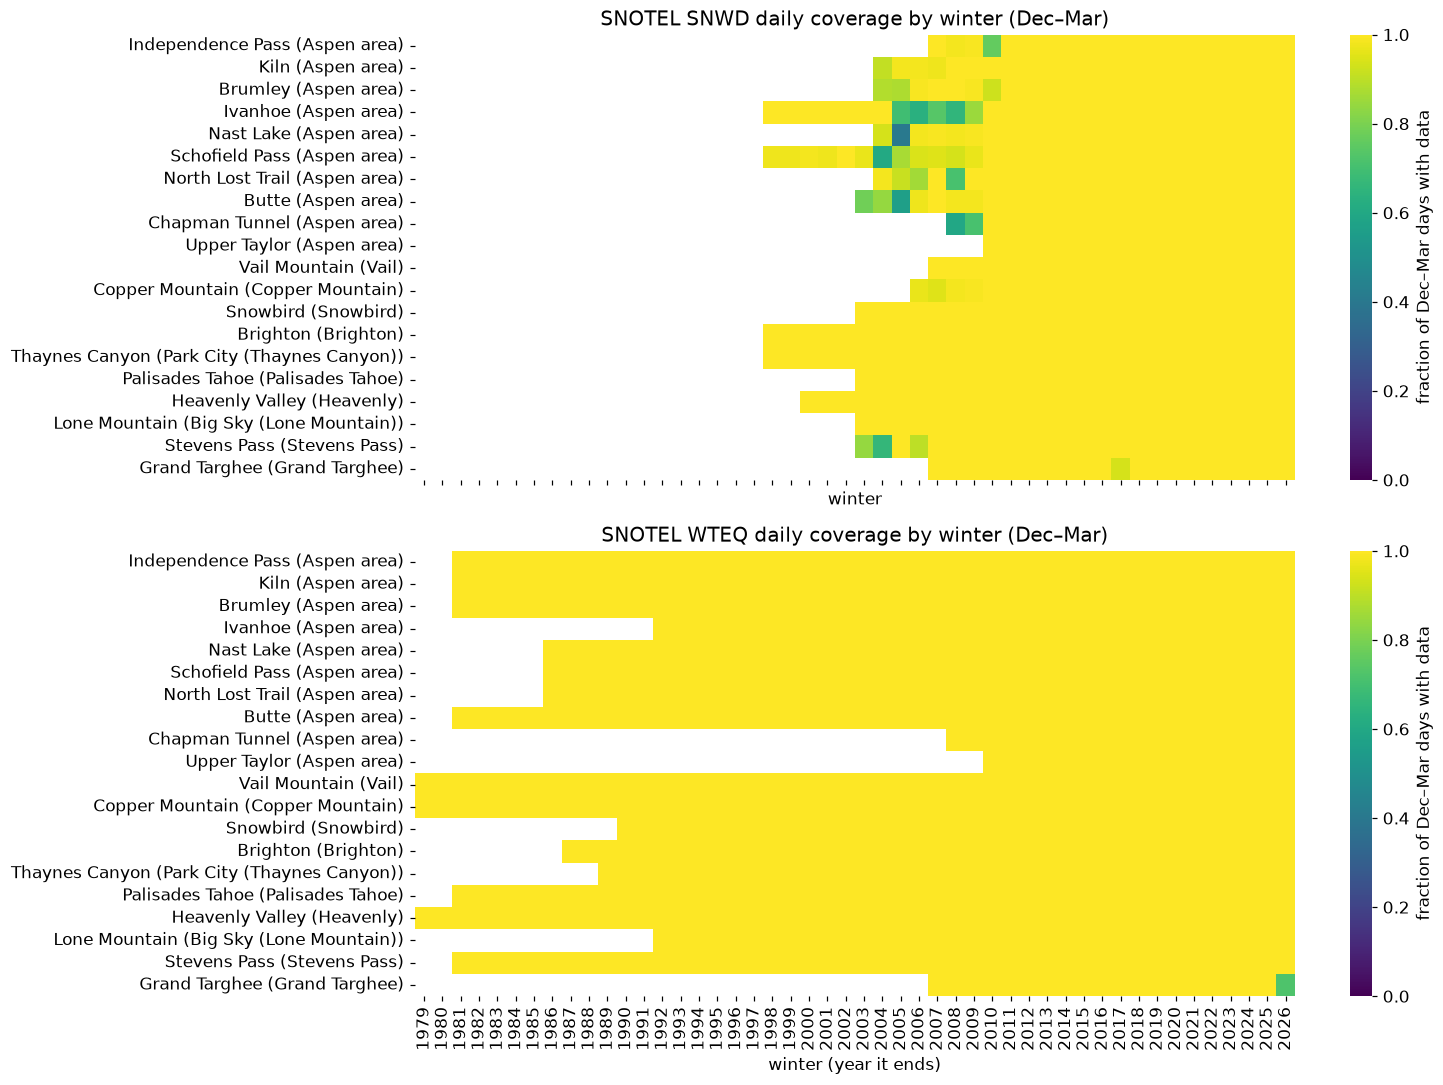

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
for ax, el in zip(axes, ["SNWD", "WTEQ"]):
    frac = (days.xs(el, level="element") / 121).clip(upper=1).unstack("winter").reindex(index=CAND, columns=range(1979, 2027))
    frac.index = [f"{meta.loc[t, 'name']} ({meta.loc[t, 'group']})" for t in frac.index]
    sns.heatmap(frac, ax=ax, cmap="viridis", vmin=0, vmax=1, cbar_kws={"label": "fraction of Dec–Mar days with data"})
    ax.set_title(f"SNOTEL {el} daily coverage by winter (Dec–Mar)"); ax.set_ylabel("")
axes[1].set_xlabel("winter (year it ends)")
plt.tight_layout(); plt.show()

**Finding → D-005/D-006.** SWE (`WTEQ`) and temperature go back to ~1979–1986, but **snow depth (`SNWD`) starts
~1997–2007, depending on the station**. If the target is measured snow depth, "as many winters as possible" means
roughly 20–29 winters per station. The metadata `beginDate` often differs from when the data actually starts, in both
directions (e.g. Snowbird). **Always count the actual data.**

### 2.5 Quality flags and NRCS edits
QC flag: V valid · E edit (minor adjustment for sensor noise) · K estimate · S suspect · B back-estimate · N no profile · M missing.
QA flag: A approved (final review) · P provisional · (blank = none recorded).
Definitions are from the NRCS Report Generator CSV header (see DATA_SOURCES).

In [14]:
snwd = sn[sn.element == "SNWD"]
flag_tab = (sn.assign(qc=sn.qc_flag.fillna("∅"), qa=sn.qa_flag.fillna("∅"))
              .groupby(["element", "qc"]).size().unstack("qc", fill_value=0))
display((flag_tab.div(flag_tab.sum(axis=1), axis=0) * 100).round(1).assign(n=flag_tab.sum(axis=1)))

changed = sn[sn.orig_value.notna() & sn.value.notna() & (sn.orig_value != sn.value)]
print("Values changed by NRCS (value != orig_value), by element:")
display(changed.groupby("element").size().to_frame("n_changed").join(sn.groupby("element").size().to_frame("n_total"))
        .assign(pct=lambda d: (100 * d.n_changed / d.n_total).round(1)))
print("Largest SNWD edits (inches):")
display(changed[changed.element == "SNWD"].assign(delta=lambda d: (d.orig_value - d.value).abs())
        .nlargest(8, "delta")[["station", "date", "orig_value", "orig_qc_flag", "value", "qc_flag", "qa_flag"]])
print("Values still flagged S (suspect) after review:", (sn.qc_flag == "S").groupby(sn.element).sum().to_dict())
print("Rows with value=null but an original value present:", (sn.value.isna() & sn.orig_value.notna()).sum())

qc,C,E,G,K,M,N,S,T,V,n
element,,,,,,,,,,
PRCP,0.0,42.4,0.0,0.1,0.4,0.0,0.1,0.0,57.0,285564
PREC,0.0,32.1,0.0,0.1,0.0,0.0,0.4,0.0,67.4,285582
SNWD,0.0,30.8,0.0,0.3,0.0,0.0,1.1,0.0,67.9,171833
TAVG,56.5,0.3,0.0,0.0,0.1,0.0,0.5,0.0,42.5,242528
TMAX,56.3,0.3,0.0,0.0,0.1,0.0,0.7,0.0,42.6,242527
TMIN,56.5,0.3,0.0,0.0,0.1,0.0,0.6,0.0,42.5,242530
WTEQ,0.0,43.3,0.0,0.2,0.0,0.0,0.1,0.2,56.2,285716


Values changed by NRCS (value != orig_value), by element:


,n_changed,n_total,pct
element,,,
PRCP,68106,285564,23.8
PREC,66412,285582,23.3
SNWD,49593,171833,28.9
TAVG,424,242528,0.2
TMAX,478,242527,0.2
TMIN,788,242530,0.3
WTEQ,96070,285716,33.6


Largest SNWD edits (inches):


,station,date,orig_value,orig_qc_flag,value,qc_flag,qa_flag
1724639,1082:WY:SNTL,2019-07-23,-22951.0,S,0.0,E,NaN
1724645,1082:WY:SNTL,2019-07-29,-22920.0,S,0.0,E,NaN
1724644,1082:WY:SNTL,2019-07-28,-22902.0,S,0.0,E,NaN
1724649,1082:WY:SNTL,2019-08-02,-22900.0,S,0.0,E,NaN
1724638,1082:WY:SNTL,2019-07-22,-22872.0,S,0.0,E,NaN
1724641,1082:WY:SNTL,2019-07-25,-22872.0,S,0.0,E,NaN
1724642,1082:WY:SNTL,2019-07-26,-22863.0,S,0.0,E,NaN
1724643,1082:WY:SNTL,2019-07-27,-22853.0,S,0.0,E,NaN


Values still flagged S (suspect) after review: {'PRCP': 363, 'PREC': 1256, 'SNWD': 1834, 'TAVG': 1276, 'TMAX': 1605, 'TMIN': 1403, 'WTEQ': 261}
Rows with value=null but an original value present: 6933


**Finding → D-009.** NRCS edits catch sensor spikes, such as raw snow-depth readings of ~200 in that were edited to ~30 in.
**We use the edited `value`, and keep `orig_value` and both flags for transparency.** The cleaning notebook will
also apply its own plausibility checks, because automated "V" only means the value passed automated checks.

### 2.6 Physical plausibility screen (detection only; any fixes go in the cleaning notebook)
- Snow depth below SWE is physically impossible, since snow density would be > 1. We test `SNWD < WTEQ` when `WTEQ > 1 in`.
- Negative values, extreme values (`SNWD > 300 in`), and day-to-day jumps (`|ΔSNWD| > 24 in`).

In [15]:
w = sn.pivot_table(index=["station", "date"], columns="element", values="value").sort_index()
w["dSNWD"] = w.groupby(level="station")["SNWD"].diff()
w["density"] = w["WTEQ"] / w["SNWD"]
checks = pd.DataFrame({
    "SNWD<WTEQ (WTEQ>1)": (w.SNWD < w.WTEQ) & (w.WTEQ > 1),
    "SNWD<0": w.SNWD < 0, "WTEQ<0": w.WTEQ < 0,
    "SNWD>300": w.SNWD > 300, "|ΔSNWD|>24": w.dSNWD.abs() > 24,
    "TAVG<-40F or >80F": (w.TAVG < -40) | (w.TAVG > 80),
}).groupby(level="station").sum()
checks.insert(0, "name", meta["name"])
display(checks.reindex(CAND))
dens = w.loc[(w.SNWD > 10) & (w.WTEQ > 1), "density"]
print("Snow density (SWE/depth) where depth>10in: quantiles", dens.quantile([.01, .05, .5, .95, .99]).round(2).to_dict())

,name,SNWD<WTEQ (WTEQ>1),SNWD<0,WTEQ<0,SNWD>300,|ΔSNWD|>24,TAVG<-40F or >80F
station,,,,,,,
542:CO:SNTL,Independence Pass,3,0,0,0,0,52
556:CO:SNTL,Kiln,0,0,0,0,0,2
369:CO:SNTL,Brumley,2,0,0,0,0,3
547:CO:SNTL,Ivanhoe,20,0,0,0,1,1
658:CO:SNTL,Nast Lake,1,0,0,0,0,58
737:CO:SNTL,Schofield Pass,43,4,0,0,1,42
669:CO:SNTL,North Lost Trail,0,0,0,0,76,49
380:CO:SNTL,Butte,0,0,0,0,0,28
1101:CO:SNTL,Chapman Tunnel,0,0,0,0,0,0


Snow density (SWE/depth) where depth>10in: quantiles {0.01: 0.13, 0.05: 0.18, 0.5: 0.29, 0.95: 0.49, 0.99: 0.57}


## 3. Validation: how close is Open-Meteo to what SNOTEL measures?
For each candidate station, we requested ERA5-Land daily `snow_depth_mean` and `temperature_2m_mean` at the station's
lat/lon with `elevation` set to the station elevation (m), for 1995–2026. Comparison is Dec–Mar only.
Units are converted only for this comparison: SNOTEL in → cm, °F → °C.

In [16]:
om = {}
for trip in CAND:
    r = meta.loc[trip]
    p = dict(latitude=r.latitude, longitude=r.longitude, elevation=float(r.elev_m), start_date="1995-01-01",
             end_date="2026-06-30", daily=["snow_depth_mean", "temperature_2m_mean"], models="era5_land", timezone="auto")
    om[trip] = parse.open_meteo_daily(open_meteo(p, name=f"val_era5land_{trip.replace(':', '_')}"))

obs = w[["SNWD", "TAVG"]].copy()
obs["SNWD_cm"] = obs.SNWD * 2.54; obs["TAVG_C"] = (obs.TAVG - 32) * 5 / 9

def compare(trip, lag=0):
    o = obs.xs(trip, level="station")
    m = om[trip].shift(lag)  # lag>0: compare SNOTEL day t with model day t-lag
    j = o.join(m, how="inner"); j = j[j.index.month.isin([12, 1, 2, 3])]
    sd = j[["SNWD_cm", "snow_depth_mean"]].dropna(); sd = sd.assign(model_cm=sd.snow_depth_mean * 100)
    tt = j[["TAVG_C", "temperature_2m_mean"]].dropna()
    return {"n_depth": len(sd), "r_depth": sd.SNWD_cm.corr(sd.model_cm),
            "obs_mean_cm": sd.SNWD_cm.mean(), "model_mean_cm": sd.model_cm.mean(),
            "bias_%": 100 * (sd.model_cm.mean() / sd.SNWD_cm.mean() - 1), "MAE_cm": (sd.model_cm - sd.SNWD_cm).abs().mean(),
            "r_temp": tt.TAVG_C.corr(tt.temperature_2m_mean), "temp_bias_C": (tt.temperature_2m_mean - tt.TAVG_C).mean()}

val = pd.DataFrame({t: compare(t) for t in CAND}).T.astype(float)
val.insert(0, "name", meta["name"]); val.insert(1, "group", meta["group"])
val.round(2)

,name,group,n_depth,r_depth,obs_mean_cm,model_mean_cm,bias_%,MAE_cm,r_temp,temp_bias_C
542:CO:SNTL,Independence Pass,Aspen area,2392.0,0.93,99.88,77.52,-22.38,22.55,0.92,0.70
556:CO:SNTL,Kiln,Aspen area,2769.0,0.94,78.97,76.14,-3.59,8.14,0.93,-0.27
369:CO:SNTL,Brumley,Aspen area,2748.0,0.90,79.76,73.41,-7.95,11.77,0.91,-0.62
547:CO:SNTL,Ivanhoe,Aspen area,3342.0,0.91,100.11,76.03,-24.05,24.38,0.92,-1.20
658:CO:SNTL,Nast Lake,Aspen area,2701.0,0.85,57.86,76.06,31.47,19.89,0.67,0.17
737:CO:SNTL,Schofield Pass,Aspen area,3409.0,0.93,162.87,81.92,-49.71,80.99,0.94,-0.87
669:CO:SNTL,North Lost Trail,Aspen area,2723.0,0.55,104.42,80.58,-22.83,25.65,0.77,-1.87
380:CO:SNTL,Butte,Aspen area,2803.0,0.94,90.79,78.62,-13.41,13.90,0.12,-3.63
1101:CO:SNTL,Chapman Tunnel,Aspen area,2219.0,0.93,88.41,79.95,-9.56,11.15,0.92,-0.12
1141:CO:SNTL,Upper Taylor,Aspen area,2061.0,0.93,85.25,70.45,-17.36,16.45,0.96,-0.57


In [17]:
# Date alignment check: does SNOTEL's daily stamp line up with Open-Meteo's local calendar day?
# Levels are highly autocorrelated, so we correlate day-to-day CHANGES in depth at several lags.
def lag_corr(trip, lags=range(-2, 3)):
    o = obs.xs(trip, level="station")["SNWD_cm"].diff()
    m = (om[trip]["snow_depth_mean"] * 100).diff()
    out = {}
    for L in lags:
        j = pd.concat([o, m.shift(L)], axis=1, join="inner").dropna()
        j = j[j.index.month.isin([12, 1, 2, 3])]
        out[L] = j.iloc[:, 0].corr(j.iloc[:, 1])
    return out
lagtab = pd.DataFrame({meta.loc[t, "name"]: lag_corr(t) for t in CAND}).T.round(3)
lagtab.columns = [f"model shifted {L:+d} d" for L in lagtab.columns]
lagtab

,model shifted -2 d,model shifted -1 d,model shifted +0 d,model shifted +1 d,model shifted +2 d
Independence Pass,0.052,0.500,0.465,-0.062,-0.087
Kiln,0.102,0.521,0.436,-0.034,-0.061
Brumley,0.071,0.492,0.420,-0.075,-0.081
Ivanhoe,0.125,0.521,0.353,-0.042,-0.061
Nast Lake,0.130,0.447,0.404,0.002,-0.040
Schofield Pass,0.148,0.658,0.407,-0.047,-0.073
North Lost Trail,0.006,0.141,-0.004,-0.011,-0.019
Butte,0.140,0.579,0.421,-0.024,-0.062
Chapman Tunnel,0.112,0.531,0.378,-0.066,-0.081
Upper Taylor,0.150,0.614,0.453,-0.049,-0.092


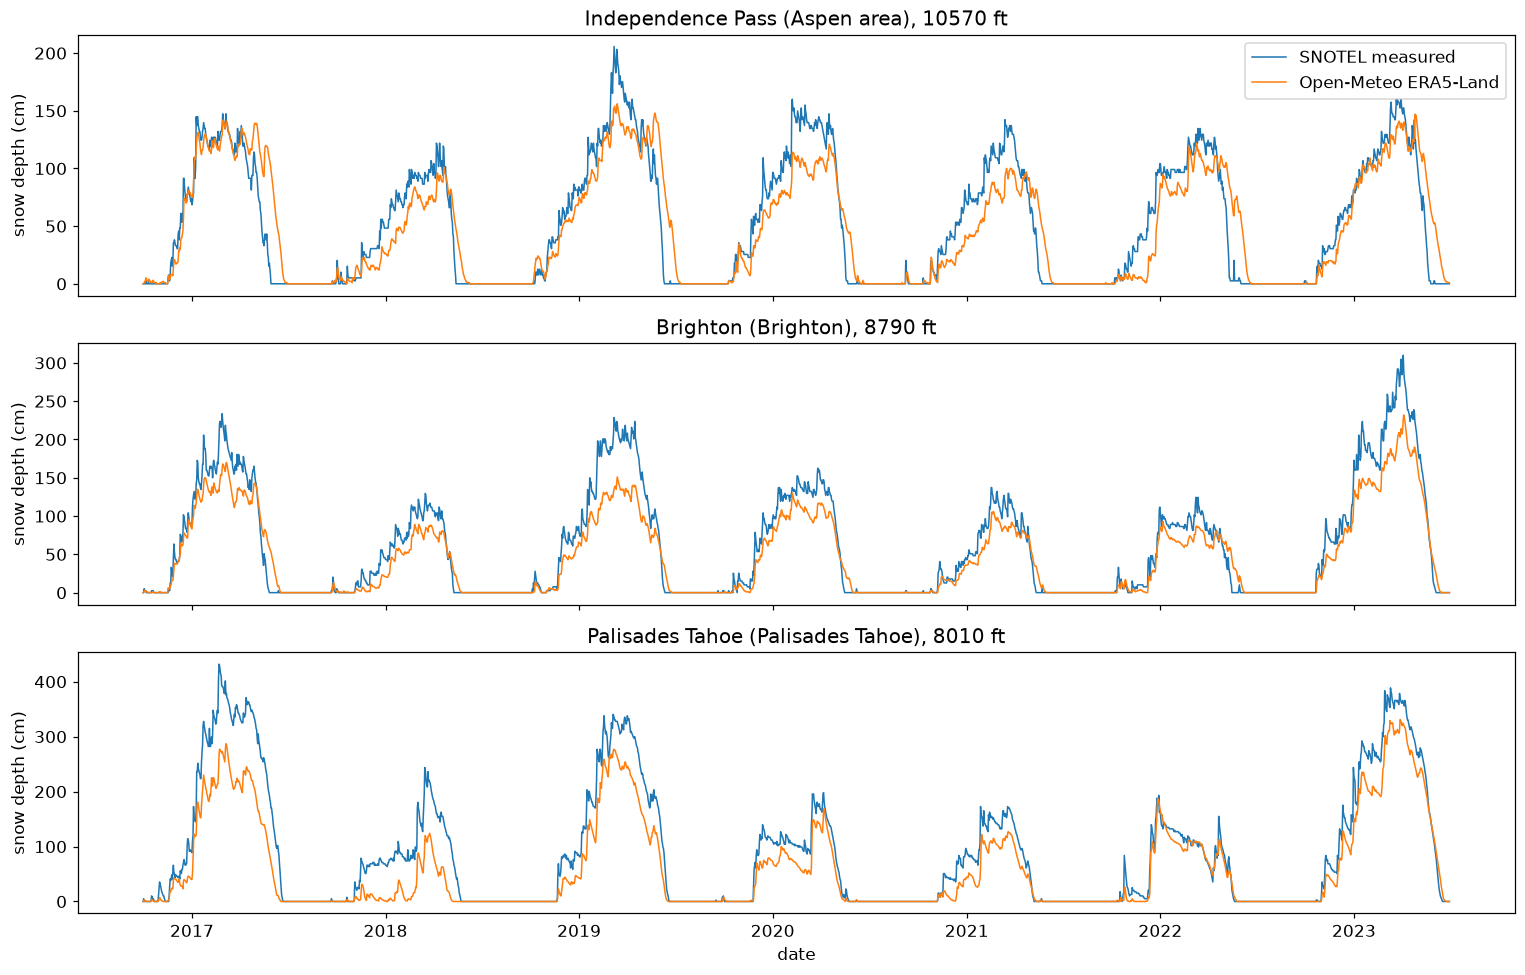

In [18]:
SHOW = ["542:CO:SNTL", "366:UT:SNTL", "784:CA:SNTL"]
fig, axes = plt.subplots(len(SHOW), 1, figsize=(14, 9), sharex=True)
for ax, t in zip(axes, SHOW):
    o = obs.xs(t, level="station")["SNWD_cm"].loc["2016-10-01":"2023-06-30"]
    m = (om[t]["snow_depth_mean"] * 100).loc["2016-10-01":"2023-06-30"]
    ax.plot(o.index, o, lw=1, label="SNOTEL measured")
    ax.plot(m.index, m, lw=1, label="Open-Meteo ERA5-Land")
    ax.set_title(f"{meta.loc[t, 'name']} ({meta.loc[t, 'group']}), {int(meta.loc[t, 'elevation'])} ft"); ax.set_ylabel("snow depth (cm)")
axes[0].legend(loc="upper right"); axes[-1].set_xlabel("date")
plt.tight_layout(); plt.show()

**Finding.**
- **Snow depth:** ERA5-Land tracks the *shape* of the season well. Dec–Mar daily r = 0.85–0.96 at 18 of 20 stations; the
  exceptions are North Lost Trail (0.55) and Nast Lake (0.85). But it is **biased low almost everywhere**: −4 % (Kiln) to −59 % (Snowbird), and
  −40 % at Palisades Tahoe. It overestimates only at low/sheltered sites (Nast Lake +31 %, Stevens Pass +8 %). So reanalysis depth
  cannot stand in for measured depth on its own, which supports using SNOTEL as ground truth (D-005).
- **Temperature:** r ≈ 0.9 at most stations, but **Butte has r = 0.12** and Nast Lake 0.67. Station temperature sensors have problems (see the
  flag "C" = sensor-equation correction on ~56 % of SNOTEL temperatures, and the known mid-2000s sensor bias). This favours Open-Meteo for temperature features.
- **Date alignment:** for day-to-day *changes* in depth, the correlation peaks at **model shifted −1 day** for 19 of 20 stations (Vail is the only exception).
  SNOTEL's value dated *t* matches Open-Meteo's daily mean for *t+1*. This is consistent with SNOTEL reporting an end-of-day
  reading while Open-Meteo reports a mean over the day. **The cleaning notebook must align them** (see the verification notebook 01b).
- North Lost Trail and Vail Mountain show weak change-correlation at every lag, and they have the most > 24 in day-to-day jumps (§2.6).
  Their depth sensors are noisy.

## 4. Aspen as one resort: which station(s) represent it?
Aspen's four ski areas sit within ~10 km of each other, so one ERA5-Land grid cell (~9 km) covers most of them. No SNOTEL station
is *on* an Aspen ski area. Below are the candidates' distances to each ski area, their elevations, snow-depth record lengths, and how strongly
their snow depths co-vary.

,name,elev_ft,Aspen Mountain,Aspen Highlands,Buttermilk,Snowmass,n_good_SNWD,first_good_SNWD,r_vs_ERA5Land
1101:CO:SNTL,Chapman Tunnel,10090,18.3,21.4,20.9,28.1,17,2010,0.934
542:CO:SNTL,Independence Pass,10570,21.6,24.1,25.8,32.6,19,2007,0.930
658:CO:SNTL,Nast Lake,8710,21.9,24.8,24.0,30.9,22,2004,0.849
1141:CO:SNTL,Upper Taylor,10710,22.6,23.2,25.8,29.9,17,2010,0.932
556:CO:SNTL,Kiln,9610,22.7,25.6,24.5,31.1,23,2004,0.942
547:CO:SNTL,Ivanhoe,10540,26.0,29.1,28.5,35.6,25,1998,0.913
369:CO:SNTL,Brumley,10570,26.1,28.9,30.4,37.5,23,2004,0.897
737:CO:SNTL,Schofield Pass,10640,27.5,24.9,26.7,23.2,28,1998,0.927
669:CO:SNTL,North Lost Trail,9190,30.5,27.4,28.2,22.1,22,2004,0.553
380:CO:SNTL,Butte,10190,34.4,33.0,35.4,34.9,22,2004,0.942


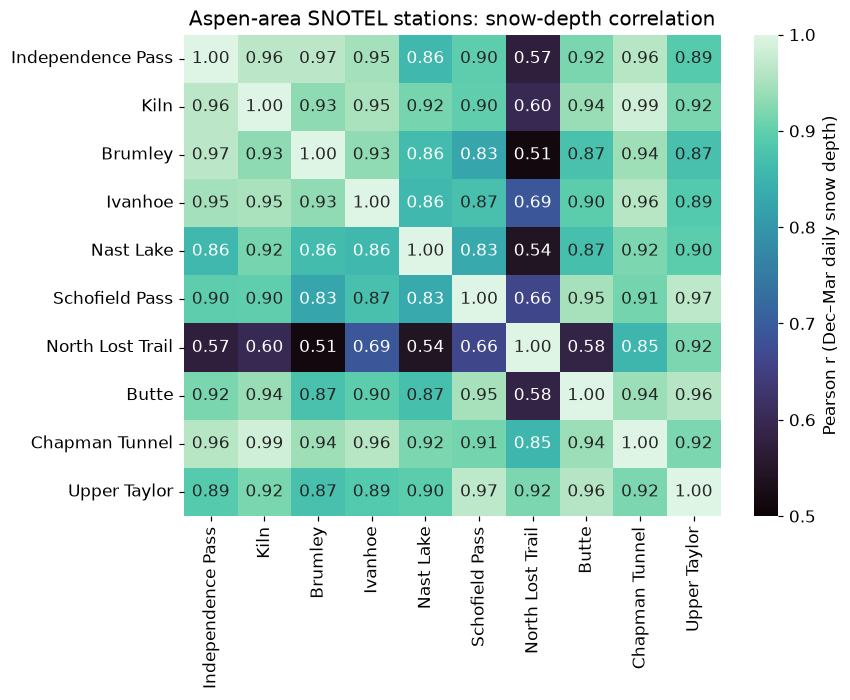

In [19]:
aspen_st = [t for t, g in sites.CANDIDATE_STATIONS.items() if g == "Aspen area"]
dist = pd.DataFrame({a: [km((meta.loc[t, "latitude"], meta.loc[t, "longitude"]), sites.SKI_AREAS[a]) for t in aspen_st]
                     for a in ["Aspen Mountain", "Aspen Highlands", "Buttermilk", "Snowmass"]}, index=aspen_st).round(1)
dist.insert(0, "name", meta.loc[aspen_st, "name"]); dist.insert(1, "elev_ft", meta.loc[aspen_st, "elevation"].astype(int))
dist["n_good_SNWD"] = wide.loc[aspen_st, "SNWD"]; dist["first_good_SNWD"] = first.loc[aspen_st, "SNWD"]
dist["r_vs_ERA5Land"] = val.loc[aspen_st, "r_depth"].round(3)
display(dist.sort_values("Aspen Mountain"))

S = obs["SNWD_cm"].unstack("station")[aspen_st]
S = S[S.index.month.isin([12, 1, 2, 3])]
S.columns = meta.loc[aspen_st, "name"]
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(S.corr(min_periods=500), annot=True, fmt=".2f", cmap="mako", vmin=0.5, vmax=1, ax=ax,
            cbar_kws={"label": "Pearson r (Dec–Mar daily snow depth)"})
ax.set_title("Aspen-area SNOTEL stations: snow-depth correlation"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Finding → D-008 (open).** No station is closer than 18 km to an Aspen ski area. The candidates that combine a long record, good
agreement with ERA5-Land, and ski-terrain elevation are:
- **Ivanhoe**: 25 winters from 1998, r = 0.91, 10,540 ft, 26 km. Longest Aspen-side record, but it is east of the Divide (Fryingpan headwaters).
- **Kiln**: 23 winters from 2004, r = 0.94, smallest bias (−4 %), 9,610 ft.
- **Independence Pass**: only 19 winters (from 2007).
- **Schofield Pass**: has the longest record (28 winters from 1998) but sits on the Crested Butte/Marble side and shows a −50 % bias. That is a very
  snowy site, not typical of Aspen.

A fixed-membership composite is possible from 2004 on (Kiln, Brumley, Nast Lake, Ivanhoe all have 2004+). Before 2004, only Ivanhoe and
Schofield exist, so a composite back to 1998 would change which stations it contains partway through. **Trade-off for the group: Ivanhoe alone, 1998+ (25 winters),
or a fixed composite, 2004+ (≈22 winters).**

## 5. Choosing the other two resorts (D-007)
Criteria: (1) a long measured snow-depth record, (2) a **different snow climate** from Aspen, so we can test whether accuracy
differs by resort, (3) the station is at or next to the resort, (4) Open-Meteo tracks it reasonably well.

In [20]:
others = [t for t, g in sites.CANDIDATE_STATIONS.items() if g != "Aspen area"]
climate = {"Vail": "continental (CO)", "Copper Mountain": "continental (CO)", "Snowbird": "intermountain (UT)",
           "Brighton": "intermountain (UT)", "Park City (Thaynes Canyon)": "intermountain (UT)",
           "Palisades Tahoe": "maritime (Sierra)", "Heavenly": "maritime/rain-shadow (Sierra)",
           "Big Sky (Lone Mountain)": "northern Rockies (MT)", "Stevens Pass": "maritime (Cascades)",
           "Grand Targhee": "northern Rockies (WY)"}
cmp5 = pd.DataFrame({"resort": meta.loc[others, "group"], "station": meta.loc[others, "name"],
                     "elev_ft": meta.loc[others, "elevation"].astype(int),
                     "snow_climate": [climate[g] for g in meta.loc[others, "group"]],
                     "n_good_SNWD": wide.loc[others, "SNWD"], "first_good_SNWD": first.loc[others, "SNWD"],
                     "r_depth_vs_ERA5Land": val.loc[others, "r_depth"].round(3), "bias_%": val.loc[others, "bias_%"].round(0)})
cmp5.sort_values("n_good_SNWD", ascending=False)

,resort,station,elev_ft,snow_climate,n_good_SNWD,first_good_SNWD,r_depth_vs_ERA5Land,bias_%
366:UT:SNTL,Brighton,Brighton,8790,intermountain (UT),29,1998,0.912,-26.0
814:UT:SNTL,Park City (Thaynes Canyon),Thaynes Canyon,9260,intermountain (UT),29,1998,0.903,-33.0
518:CA:SNTL,Heavenly,Heavenly Valley,8540,maritime/rain-shadow (Sierra),27,2000,0.955,-35.0
766:UT:SNTL,Snowbird,Snowbird,9170,intermountain (UT),24,2003,0.903,-59.0
784:CA:SNTL,Palisades Tahoe,Palisades Tahoe,8010,maritime (Sierra),24,2003,0.913,-40.0
590:MT:SNTL,Big Sky (Lone Mountain),Lone Mountain,8820,northern Rockies (MT),24,2003,0.914,-36.0
791:WA:SNTL,Stevens Pass,Stevens Pass,3940,maritime (Cascades),23,2003,0.958,8.0
415:CO:SNTL,Copper Mountain,Copper Mountain,10500,continental (CO),21,2006,0.921,-17.0
842:CO:SNTL,Vail,Vail Mountain,10290,continental (CO),20,2007,0.904,-27.0
1082:WY:SNTL,Grand Targhee,Grand Targhee,9260,northern Rockies (WY),20,2007,0.929,-47.0


## 6. Data volume and lineage
Everything this notebook downloaded, from `data/raw/MANIFEST.csv`.

In [21]:
man = lineage.manifest()
latest = man.drop_duplicates("url", keep="last")
print(f"{len(latest)} distinct requests | {latest.bytes.sum() / 1e6:.1f} MB raw JSON on disk")
display(latest.groupby(["source", "http_status"]).agg(files=("file", "size"), MB=("bytes", lambda b: round(b.sum() / 1e6, 2))))
latest[["fetched_utc", "source", "name", "bytes", "http_status"]].head(10)

81 distinct requests | 157.5 MB raw JSON on disk


files     MB
source     http_status              
open_meteo 200             57    8.6
           400              2    0.0
snotel     200             22  148.9

,fetched_utc,source,name,bytes,http_status
0,2026-11-10T00:23:44+00:00,open_meteo,oneday_stanton_best_match_2021-01-10,508,200
1,2026-11-10T00:23:45+00:00,open_meteo,oneday_stanton_era5_2021-01-10,502,200
2,2026-11-10T00:23:45+00:00,open_meteo,oneday_stanton_era5_land_2021-01-10,507,200
3,2026-11-10T00:23:46+00:00,open_meteo,oneday_stanton_era5_seamless_2021-01-10,510,200
4,2026-11-10T00:23:47+00:00,open_meteo,oneday_stanton_ecmwf_ifs_2021-01-10,509,200
5,2026-11-10T00:23:48+00:00,open_meteo,oneday_stanton_cerra_2021-01-10,509,200
6,2026-11-10T00:23:49+00:00,open_meteo,oneday_aspen_best_match_2021-01-10,512,200
7,2026-11-10T00:23:50+00:00,open_meteo,oneday_aspen_era5_2021-01-10,506,200
8,2026-11-10T00:23:51+00:00,open_meteo,oneday_aspen_era5_land_2021-01-10,510,200
9,2026-11-10T00:23:52+00:00,open_meteo,oneday_aspen_era5_seamless_2021-01-10,513,200


## 7. Summary of findings → decisions

| # | Finding (evidence in this notebook) | Decision |
|---|---|---|
| 1 | `best_match` = ERA5-Land through 2016 and = IFS from 2017 (100 % day match), causing a jump of several °C (§1.2) | **D-002** pin models; never `best_match` |
| 2 | CERRA ends 2021-06-30 and is Europe only; IFS snow depth only from 2025 (§1.2) | ERA5 / ERA5-Land only |
| 3 | `elevation=` corrects temperature only; snow is a grid-cell value (§1.3) | **D-003** measured snow from SNOTEL |
| 4 | ERA5 = atmosphere vars, ERA5-Land = temp + snow depth; freezing level / visibility empty (§1.4) | feature list for notebook 02/03 |
| 5 | No archived 30-day forecasts: seasonal data starts 2025-09; historical forecasts start 2018 (§1.5) | **D-004** baselines: climatology (train winters only) + persistence |
| 6 | SNOTEL snow depth starts 1997–2010 depending on station; SWE/temp start ~1979–1986; metadata `beginDate` is unreliable (§2.2–2.4) | **D-005/D-006** target SNWD → ~20–29 winters per station |
| 7 | 29 % of SNWD and 34 % of SWE values were edited by NRCS; raw sensor garbage reaches −22,951 in; 1,834 SNWD values still suspect; 6,933 values nulled by NRCS (§2.5) | **D-009** fetch everything, use edited value, filter in documented cleaning |
| 8 | Impossible/odd values: depth < SWE, negative depth, > 24 in daily jumps, extreme temperatures, all concentrated at a few stations (§2.6) | handled in notebook 02 |
| 9 | ERA5-Land depth r ≈ 0.9 but biased low (−4 % to −59 %); temperature r ≈ 0.9 except Butte 0.12 (§3) | SNOTEL = target; Open-Meteo = features |
| 10 | SNOTEL day *t* ↔ Open-Meteo daily mean day *t+1* (lag test, 19 of 20 stations) (§3) | align dates in notebook 02 |
| 11 | Aspen: Ivanhoe alone gives 1998+; a fixed composite gives 2004+ (§4) | **D-008**: group to choose |
| 12 | Longest records outside CO: Brighton & Thaynes 29 winters (1998+), Heavenly 27 (2000+); Palisades Tahoe only 24 (2003+) (§5) | **D-007**: revisit Palisades vs Heavenly / Stevens Pass |

Raw data volume and lineage: see §6. All files are verified by `src/verify_raw.py`.